# Loan default prediction with PySpark

**Beginner-friendly Google Colab notebook.** Upload `Loan_default 2.csv` when prompted, then run the cells from top to bottom.

The goal is to predict **default (`1`) or no default (`0`)** from applicant and loan details. The notebook uses **PySpark DataFrames and Spark ML** for loading, cleaning, feature preparation, training, and predictions. Small result tables are brought into pandas only to draw charts and calculate evaluation measures.

A prediction is an estimate, not a guarantee. The CSV does not separately prove that every no-default loan was fully repaid.

## Step 1 — Install PySpark and upload the CSV

Colab normally has Python, pandas, matplotlib, scikit-learn, and Java. The code installs PySpark if needed. Click **Choose Files** and select `Loan_default 2.csv`. Outside Colab, put that CSV beside this notebook.

In [1]:
import importlib.util
import subprocess
import sys
if importlib.util.find_spec("pyspark") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyspark>=3.5,<5"])

from pathlib import Path
import shutil
if shutil.which("java") is None:
    raise RuntimeError("Java 17+ is required for PySpark. In Colab, switch to a standard Python runtime and rerun.")

try:
    from google.colab import files
except ImportError:
    csv_path = Path("Loan_default 2.csv")
    if not csv_path.exists():
        raise FileNotFoundError("Put Loan_default 2.csv beside the notebook.")
else:
    uploaded = files.upload()
    csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
    if not csv_names:
        raise ValueError("Please upload the loan CSV file.")
    csv_path = Path(csv_names[0])

print("Using:", csv_path)

Using: Loan_default 2.csv


## Step 2 — Start Spark and inspect the data

Spark reads the CSV directly. `Default` is the target column: `1` means default, `0` means no default. `LoanID` is an identifier and will not be used to predict.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder.master("local[2]")
         .appName("Loan default prediction")
         .config("spark.driver.memory", "2g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.enabled", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
loans = spark.read.option("header", True).option("inferSchema", True).csv(str(csv_path))
print("Rows:", loans.count(), "Columns:", len(loans.columns))
loans.printSchema()
loans.show(5, truncate=False)

/usr/local/lib/python3.11/site-packages/pyspark/bin/load-spark-env.sh: line 68: ps: command not found


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/27 10:44:19 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Rows: 255347 Columns: 18
root
 |-- LoanID: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Income: integer (nullable = true)
 |-- LoanAmount: integer (nullable = true)
 |-- CreditScore: integer (nullable = true)
 |-- MonthsEmployed: integer (nullable = true)
 |-- NumCreditLines: integer (nullable = true)
 |-- InterestRate: double (nullable = true)
 |-- LoanTerm: integer (nullable = true)
 |-- DTIRatio: double (nullable = true)
 |-- Education: string (nullable = true)
 |-- EmploymentType: string (nullable = true)
 |-- MaritalStatus: string (nullable = true)
 |-- HasMortgage: string (nullable = true)
 |-- HasDependents: string (nullable = true)
 |-- LoanPurpose: string (nullable = true)
 |-- HasCoSigner: string (nullable = true)
 |-- Default: integer (nullable = true)

+----------+---+------+----------+-----------+--------------+--------------+------------+--------+--------+-----------+--------------+-------------+-----------+-------------+-----------+-----------+------

## Step 3 — Check the target and draw first graphs

The dataset has many more no-default records than defaults. This imbalance means accuracy alone can be misleading.

 Default  count
       0 225694
       1  29653


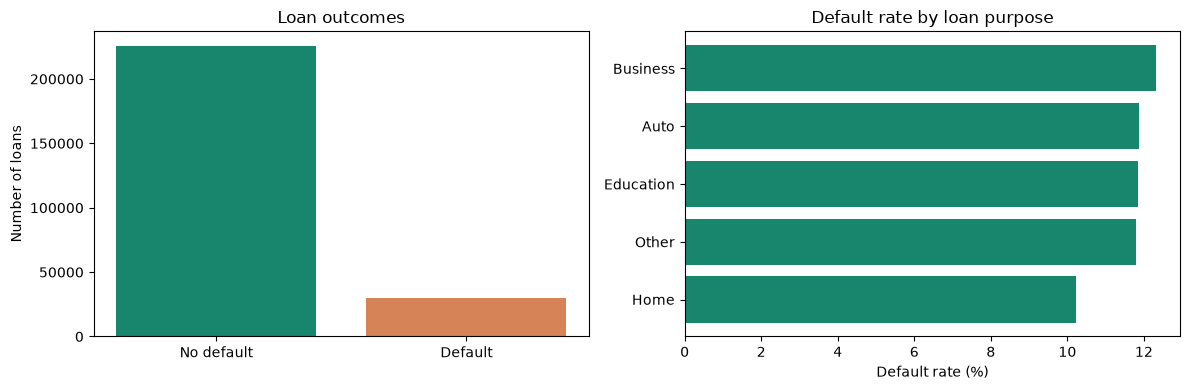

In [3]:
outcomes = loans.groupBy("Default").count().orderBy("Default").toPandas()
purposes = (loans.groupBy("LoanPurpose")
            .agg(F.avg("Default").alias("default_rate"))
            .orderBy("default_rate").toPandas())
print(outcomes.to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(["No default", "Default"], outcomes["count"], color=["#18856d", "#d78358"])
axes[0].set(title="Loan outcomes", ylabel="Number of loans")
axes[1].barh(purposes["LoanPurpose"], purposes["default_rate"] * 100, color="#18856d")
axes[1].set(title="Default rate by loan purpose", xlabel="Default rate (%)")
plt.tight_layout()
plt.show()

## Step 4 — Clean, sample, and split

We keep valid unique loans, use **200,000 rows**, and randomly split into roughly **70% training, 15% validation, and 15% test**. This CSV has no date column, so it cannot be tested on future loans by time.

In [4]:
NUMERIC = ["Age", "Income", "LoanAmount", "CreditScore", "MonthsEmployed",
           "NumCreditLines", "InterestRate", "LoanTerm", "DTIRatio"]
CATEGORICAL = ["Education", "EmploymentType", "MaritalStatus", "HasMortgage",
               "HasDependents", "LoanPurpose", "HasCoSigner"]
FEATURES = NUMERIC + CATEGORICAL
required = set(FEATURES + ["LoanID", "Default"])
missing = required - set(loans.columns)
if missing:
    raise ValueError(f"Missing CSV columns: {sorted(missing)}")

clean = (loans.dropna(subset=FEATURES + ["LoanID", "Default"])
         .filter(F.col("Default").isin(0, 1))
         .dropDuplicates(["LoanID"]))
print("Valid unique rows:", clean.count())
row_limit = min(200_000, clean.count())
sample = (clean.withColumn("_random", F.rand(seed=42))
          .orderBy("_random").limit(row_limit).drop("_random"))
train_df, valid_df, test_df = sample.randomSplit([0.70, 0.15, 0.15], seed=42)
train_df.cache(); valid_df.cache(); test_df.cache()
for name, part in [("Train", train_df), ("Validation", valid_df), ("Test", test_df)]:
    count = part.count()
    rate = part.agg(F.avg("Default")).first()[0]
    print(f"{name}: {count:,} rows; {rate:.1%} defaults")

Valid unique rows: 255347


Train: 139,838 rows; 11.6% defaults


Validation: 30,016 rows; 11.5% defaults


Test: 30,146 rows; 11.8% defaults


## Step 5 — Turn columns into Spark ML features

Spark ML models need one `features` vector. We encode text categories, join them with numeric columns, and scale the result. The preparation steps are fitted **only on training data** to avoid using validation or test information.

In [5]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler

indexers = [StringIndexer(inputCol=name, outputCol=name + "_index", handleInvalid="keep")
            for name in CATEGORICAL]
encoder = OneHotEncoder(inputCols=[name + "_index" for name in CATEGORICAL],
                        outputCols=[name + "_vector" for name in CATEGORICAL],
                        handleInvalid="keep")
assembler = VectorAssembler(inputCols=NUMERIC + [name + "_vector" for name in CATEGORICAL],
                            outputCol="raw_features", handleInvalid="skip")
scaler = StandardScaler(inputCol="raw_features", outputCol="features",
                        withStd=True, withMean=False)
preparation = Pipeline(stages=indexers + [encoder, assembler, scaler]).fit(train_df)
train_ready = preparation.transform(train_df).select("Default", "features").cache()
valid_ready = preparation.transform(valid_df).select("Default", "features").cache()
test_ready = preparation.transform(test_df).select("Default", "features").cache()
print("Prepared:", train_ready.count(), valid_ready.count(), test_ready.count())

Prepared: 139838 30016 30146


## Step 6 — Train three PySpark models

We compare Spark logistic regression, decision tree, and random forest. The **validation** set chooses the best model; the **test** set stays untouched until the next step.

In [6]:
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, RandomForestClassifier
from pyspark.ml.functions import vector_to_array
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)

estimators = {
    "Logistic regression": LogisticRegression(featuresCol="features", labelCol="Default", maxIter=50, regParam=0.05),
    "Decision tree": DecisionTreeClassifier(featuresCol="features", labelCol="Default",
                                             maxDepth=8, minInstancesPerNode=100, seed=42),
    "Random forest": RandomForestClassifier(featuresCol="features", labelCol="Default",
                                             numTrees=60, maxDepth=8, minInstancesPerNode=25,
                                             featureSubsetStrategy="sqrt", seed=42),
}
models = {}
validation = {}
for name, estimator in estimators.items():
    model = estimator.fit(train_ready)
    scored = model.transform(valid_ready).select(
        F.col("Default").alias("actual"), vector_to_array("probability")[1].alias("risk")).toPandas()
    actual = scored["actual"].astype(int)
    risk = scored["risk"]
    thresholds = np.linspace(0.02, 0.50, 97)
    f1_values = [f1_score(actual, risk >= value) for value in thresholds]
    threshold = float(thresholds[np.argmax(f1_values)])
    predicted = (risk >= threshold).astype(int)
    validation[name] = {
        "average_precision": average_precision_score(actual, risk),
        "roc_auc": roc_auc_score(actual, risk),
        "accuracy": accuracy_score(actual, predicted),
        "precision": precision_score(actual, predicted, zero_division=0),
        "recall": recall_score(actual, predicted, zero_division=0),
        "f1": f1_score(actual, predicted, zero_division=0),
        "threshold": threshold,
    }
    models[name] = model
    print(f"Finished {name}")
comparison = pd.DataFrame(validation).T
best_name = comparison["average_precision"].idxmax()
best_model = models[best_name]
best_threshold = float(comparison.loc[best_name, "threshold"])
print("Selected:", best_name, "| threshold:", f"{best_threshold:.1%}")
print(comparison.round(3).to_string())

Finished Logistic regression


Finished Decision tree


Finished Random forest
Selected: Logistic regression | threshold: 16.5%
                     average_precision  roc_auc  accuracy  precision  recall     f1  threshold
Logistic regression              0.308    0.747     0.802      0.286   0.476  0.357      0.165
Decision tree                    0.214    0.661     0.773      0.236   0.434  0.306      0.120
Random forest                    0.295    0.733     0.794      0.274   0.475  0.347      0.140


## Step 7 — Compare model results

**Average precision** selects the model because defaults are the smaller class. Each model's yes/no metrics below use its own validation F1 threshold.

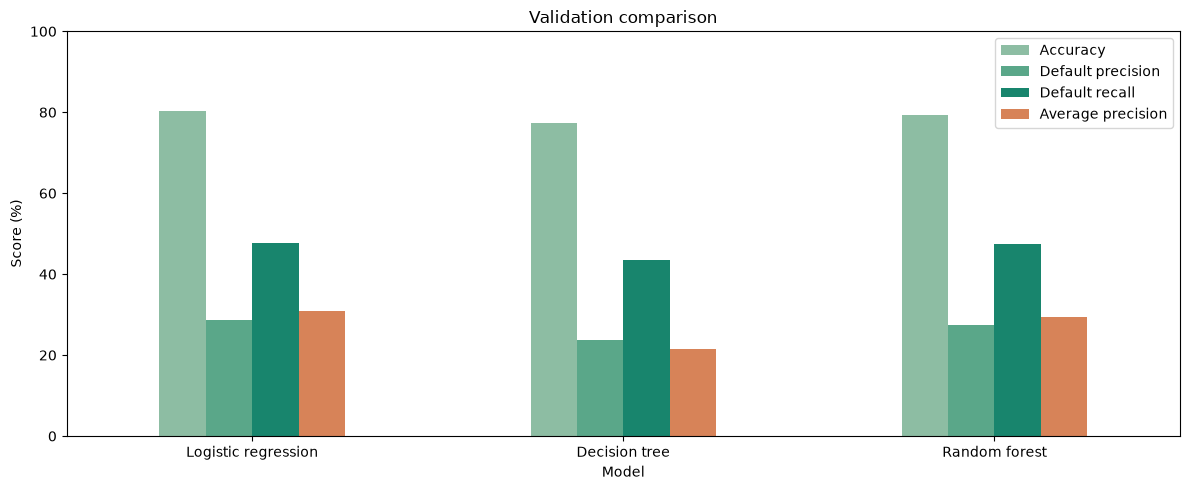

In [7]:
names = comparison.index.tolist()
metrics_to_plot = ["accuracy", "precision", "recall", "average_precision"]
plot_values = comparison[metrics_to_plot] * 100
ax = plot_values.plot(kind="bar", figsize=(12, 5), color=["#8dbda3", "#5aa789", "#18856d", "#d78358"])
ax.set(title="Validation comparison", ylabel="Score (%)", xlabel="Model", ylim=(0, 100))
ax.set_xticklabels(names, rotation=0)
ax.legend(["Accuracy", "Default precision", "Default recall", "Average precision"])
plt.tight_layout()
plt.show()

## Step 8 — Evaluate the held-out test set

We now score the selected Spark model once on the test set. The always-"no default" baseline is shown so a high accuracy number is not mistaken for good default detection.

In [8]:
test_scored = best_model.transform(test_ready).select(
    F.col("Default").alias("actual"), vector_to_array("probability")[1].alias("risk")).toPandas()
y_test = test_scored["actual"].astype(int)
risk_test = test_scored["risk"]
predicted_test = (risk_test >= best_threshold).astype(int)
results = {
    "accuracy": accuracy_score(y_test, predicted_test),
    "default_precision": precision_score(y_test, predicted_test, zero_division=0),
    "default_recall": recall_score(y_test, predicted_test, zero_division=0),
    "f1": f1_score(y_test, predicted_test, zero_division=0),
    "roc_auc": roc_auc_score(y_test, risk_test),
    "average_precision": average_precision_score(y_test, risk_test),
}
print("PySpark model:", best_name)
print("Test loans:", len(y_test))
for name, value in results.items():
    print(f"{name}: {value:.3f}")
print("Always-no-default accuracy:", f"{1 - y_test.mean():.3f}")
cm = confusion_matrix(y_test, predicted_test, labels=[0, 1])
print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)

PySpark model: Logistic regression
Test loans: 30146
accuracy: 0.798
default_precision: 0.288
default_recall: 0.485
f1: 0.361
roc_auc: 0.754
average_precision: 0.302
Always-no-default accuracy: 0.882
Confusion matrix [[TN, FP], [FN, TP]]:
 [[22340  4252]
 [ 1832  1722]]


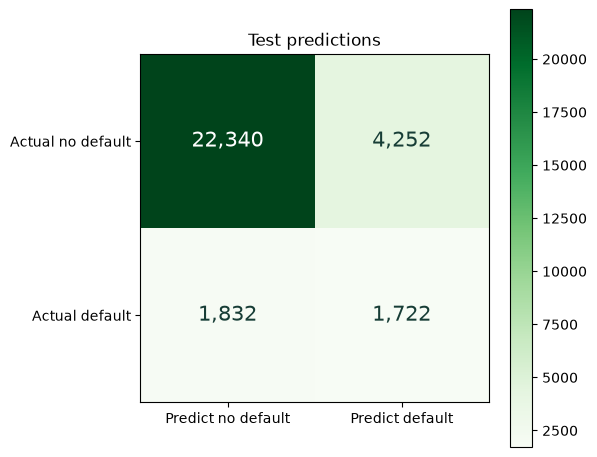

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(cm, cmap="Greens")
for (row, col), count in np.ndenumerate(cm):
    ax.text(col, row, f"{count:,}", ha="center", va="center", fontsize=15,
            color="white" if count > cm.max() / 2 else "#173d36")
ax.set_xticks([0, 1], ["Predict no default", "Predict default"])
ax.set_yticks([0, 1], ["Actual no default", "Actual default"])
ax.set_title("Test predictions")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

## Step 9 — Predict one new applicant

Change the example values to try another borrower. The Spark preprocessing pipeline and selected Spark ML model produce the risk estimate. A risk below the validation threshold is shown as **Likely to repay**; otherwise it is **At risk of not repaying**.

In [10]:
applicant = {
    "Age": 35, "Income": 70000, "LoanAmount": 50000, "CreditScore": 650,
    "MonthsEmployed": 36, "NumCreditLines": 2, "InterestRate": 12.0,
    "LoanTerm": 36, "DTIRatio": 0.4, "Education": "High School",
    "EmploymentType": "Full-time", "MaritalStatus": "Single",
    "HasMortgage": "No", "HasDependents": "No", "LoanPurpose": "Auto", "HasCoSigner": "No",
}
new_loan = spark.createDataFrame([applicant])
prepared_loan = preparation.transform(new_loan)
probability = float(best_model.transform(prepared_loan).select(
    vector_to_array("probability")[1].alias("risk")).first()["risk"])
outcome = "At risk of not repaying" if probability >= best_threshold else "Likely to repay"
print("Prediction:", outcome)
print("Estimated default probability:", f"{probability:.1%}")
print("Decision threshold:", f"{best_threshold:.1%}")

Prediction: Likely to repay
Estimated default probability: 13.2%
Decision threshold: 16.5%


## What you completed

1. Uploaded and loaded a real CSV file in PySpark.
2. Checked the target and drew exploratory graphs.
3. Prepared numeric and categorical fields with Spark ML.
4. Trained three PySpark classification models.
5. Selected a model on validation data and evaluated it on held-out test data.
6. Predicted a new applicant's default risk.

**Limitations:** The CSV's origin is not independently verified. It has no loan date for a future-time test. The model is for learning and demonstration, not a real lending decision.